# 직접 해보기: Elliptic Envelope (원본 데이터부터)

이전 노트북의 피처·함수는 쓰지 않고, 원본 CSV만으로 처음부터 진행합니다.

- `data/train.csv`: ID, V1~V30 (정답 없음)
- `data/val.csv`: ID, V1~V30, Class (사기=1)
- `data/test.csv`: ID, V1~V30
- `data/sample_submission.csv`: 제출 형식 (ID, Class)

In [6]:
%pip install tqdm
%pip install torch


Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import random
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.ensemble import IsolationForest
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings(action='ignore')

train = pd.read_csv('../data/train.csv')
val = pd.read_csv('../data/val.csv')
test = pd.read_csv('../data/test.csv')

print('train:', train.shape, '/ val:', val.shape, '/ test:', test.shape)

train: (113842, 31) / val: (28462, 32) / test: (142503, 31)


In [8]:
train.head()

,ID,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30
0,3,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.983721,-0.994972
1,4,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.418291,-0.994972
2,6,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,-0.256131,-0.994960
3,8,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,0.262698,-0.994901
4,9,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,0.994900,-0.994901


In [9]:
val.head()

,ID,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,V29,V30,Class
0,10,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,-0.255991,-0.994878,0
1,22,0.962496,0.328461,-0.171479,2.109204,1.129566,1.696038,0.107712,0.521502,-1.191311,...,0.402492,-0.048508,-1.371866,0.390814,0.199964,0.016371,-0.014605,0.168937,-0.994784,0
2,63,1.145524,0.575068,0.194008,2.598192,-0.092210,-1.044430,0.531588,-0.241888,-0.896287,...,-0.119703,-0.076510,0.691320,0.633984,0.048741,-0.053192,0.016251,0.169496,-0.994502,0
3,69,0.927060,-0.323684,0.387585,0.544474,0.246787,1.650358,-0.427576,0.615371,0.226278,...,0.079359,0.096632,-0.992569,0.085096,0.377447,0.036096,-0.005960,0.331307,-0.994467,0
4,83,-3.005237,2.600138,1.483691,-2.418473,0.306326,-0.824575,2.065426,-1.829347,4.009259,...,-0.181268,-0.163747,0.515821,0.136318,0.460054,-0.251259,-1.105751,-0.287012,-0.994373,0


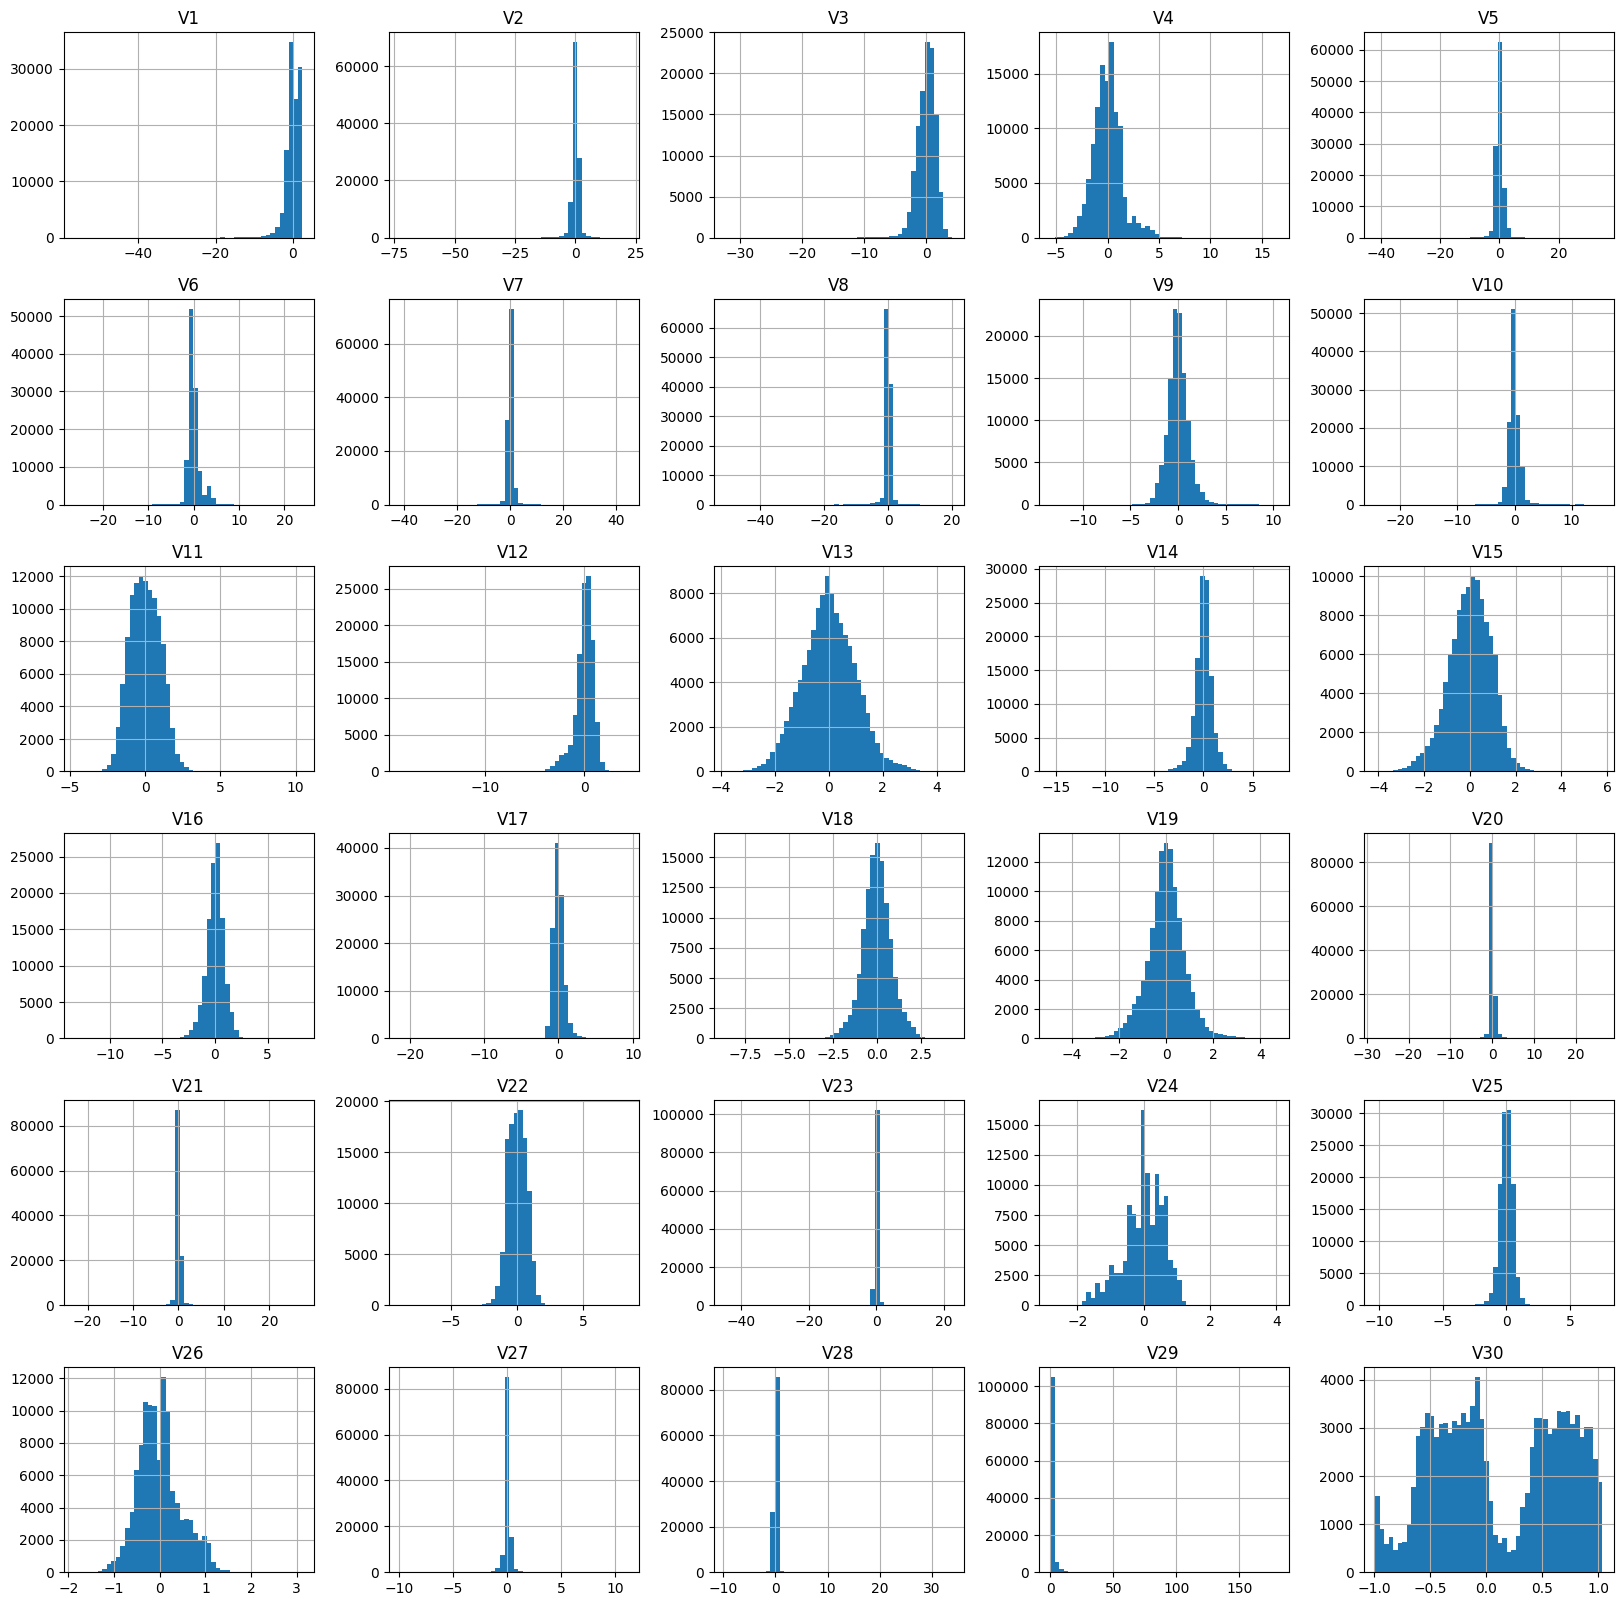

In [10]:
train.drop(columns=['ID']).hist(bins=50, figsize=(20,20))
plt.show()

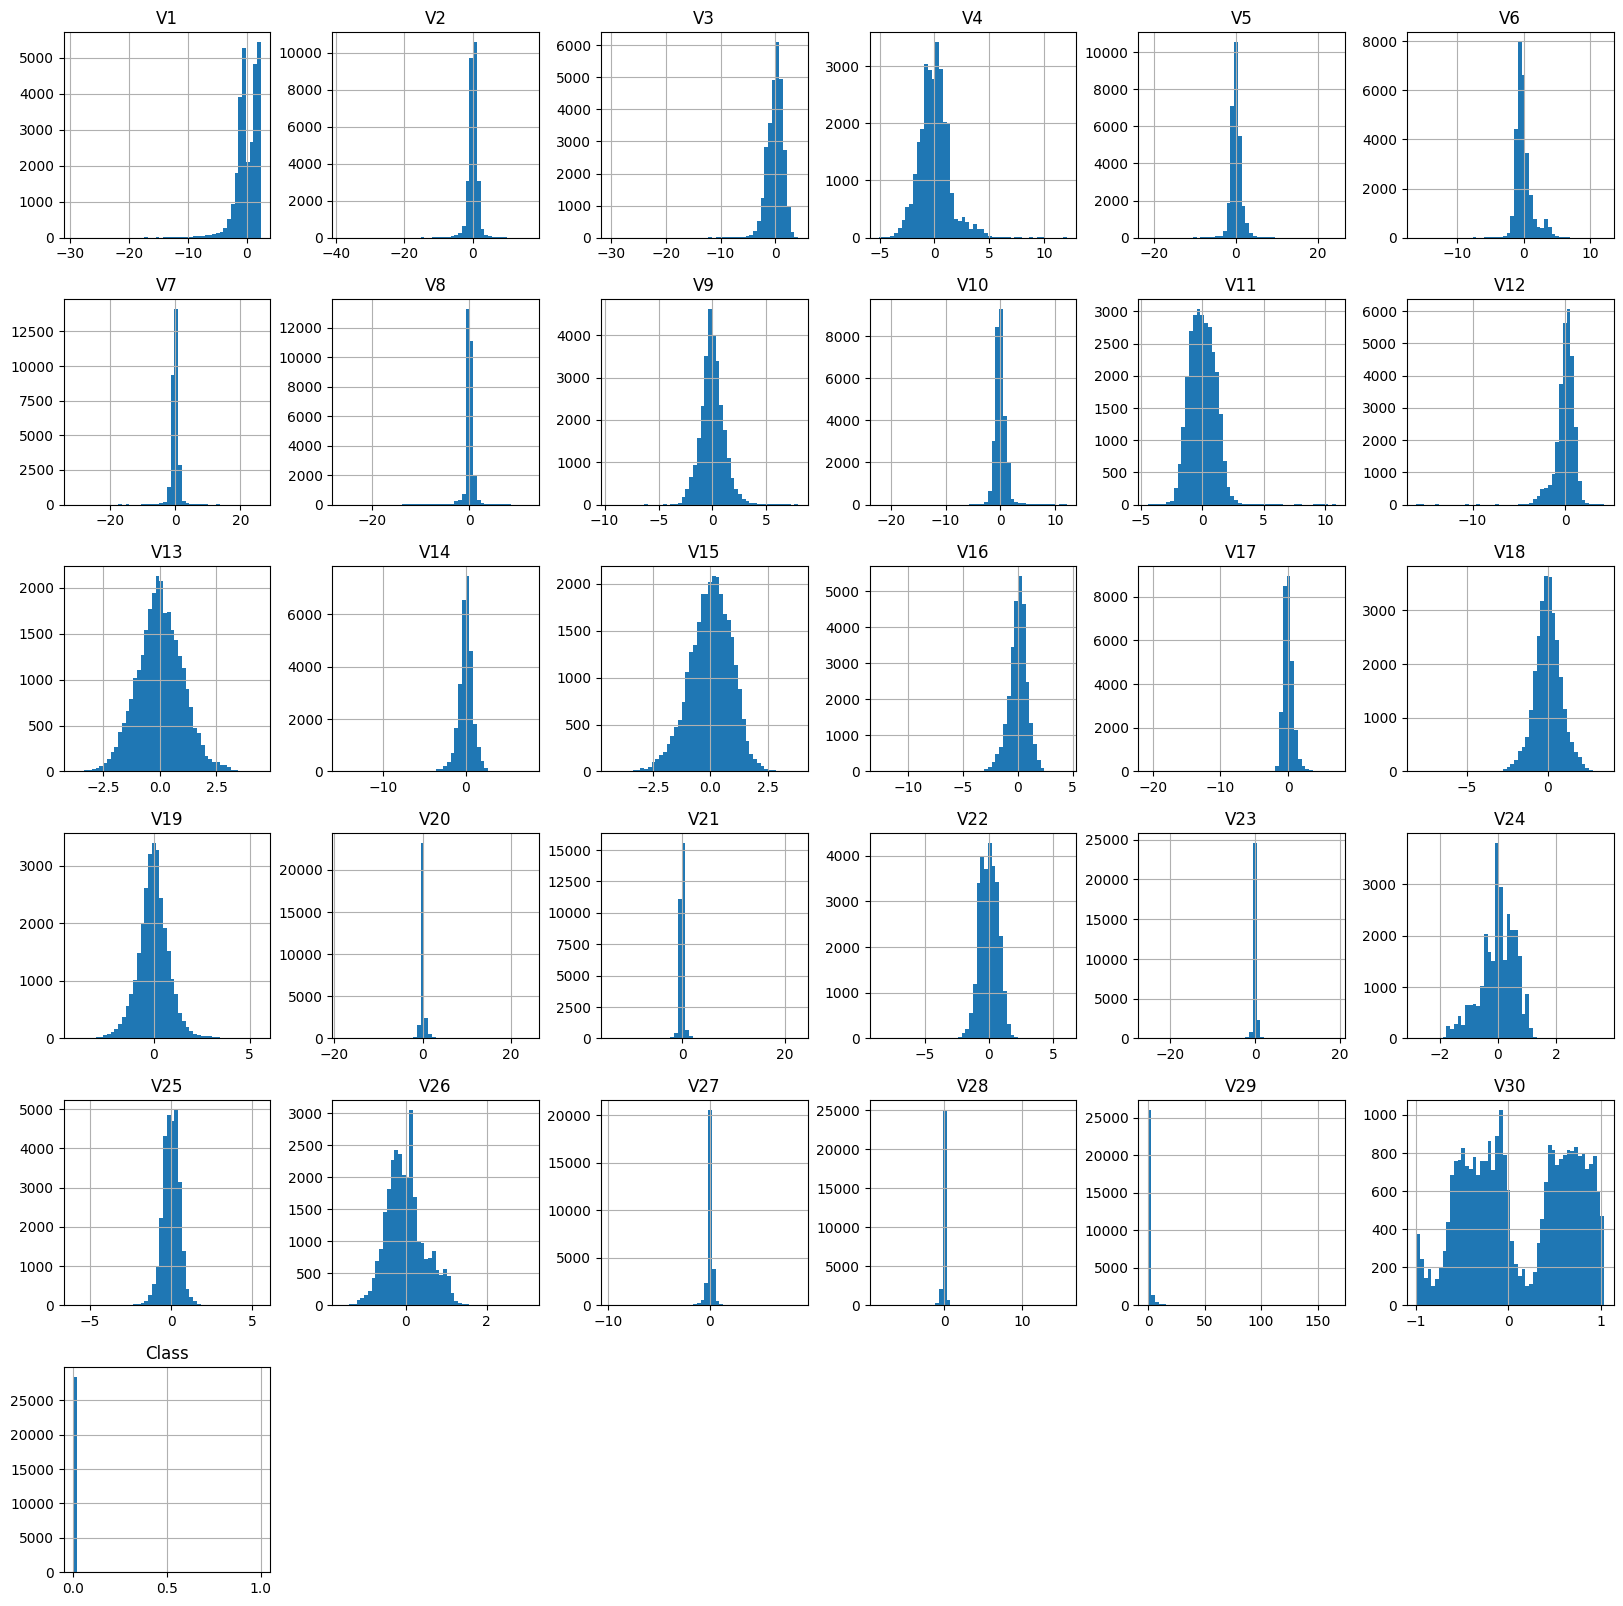

In [11]:
val.drop(columns=['ID']).hist(bins=50, figsize=(20,20))
plt.show()

In [12]:
val_normal, val_fraud=val['Class'].value_counts()
val_contamination = val_fraud / val_normal
print(f'val_contamination: {val_contamination}')

val_contamination: 0.0010551491277433877


In [13]:
train_x = train.drop(columns=["ID"])

In [14]:
pca_model=PCA(n_components=2)
pca_model.fit(train_x)
pca_x=pca_model.transform(train_x)

In [15]:
pca_x.shape

(113842, 2)

In [16]:
re_pca_x = pca_x.reshape(2,-1)
re_pca_x

array([[  4.50543791,  -0.82527886,   0.59692952, ...,  -0.93574395,
         -1.28726651,   1.26292192],
       [ -1.35067473,   1.08277948,  -1.27829526, ...,  -0.1197507 ,
         -1.48161661, -12.53317251]])

In [17]:
train_x['PCA_1']=re_pca_x[0].reshape(-1,1)
train_x['PCA_2']=re_pca_x[1].reshape(-1,1)

In [18]:
train_x.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,V29,V30,PCA_1,PCA_2
0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.983721,-0.994972,4.505438,-1.350675
1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.418291,-0.994972,-0.825279,1.082779
2,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,-0.371407,...,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,-0.256131,-0.994960,0.596930,-1.278295
3,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,1.249376,...,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,0.262698,-0.994901,-1.028132,1.252004
4,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,-0.410430,...,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,0.994900,-0.994901,-1.367485,-1.301515


In [19]:
model = EllipticEnvelope(support_fraction=0.994, contamination=val_contamination, random_state=42)
model.fit(train_x)

EllipticEnvelope(contamination=0.0010551491277433877, random_state=42,
                 support_fraction=0.994)

In [20]:
def get_pred_label(model_pred):
    model_pred = np.where(model_pred == 1, 0, model_pred)
    model_pred = np.where(model_pred == -1, 1, model_pred)
    return model_pred

In [21]:
val_x = val.drop(columns=['ID','Class']) # Input Data
val_y = val["Class"] # Label

pca_val_x = pca_model.transform(val_x)
re_pca_val_x = pca_val_x.reshape(2,-1)

val_x["PCA_1"] = re_pca_val_x[0].reshape(-1,1)
val_x["PCA_2"] = re_pca_val_x[1].reshape(-1,1)

val_pred = model.predict(val_x)
val_pred = get_pred_label(val_pred)
val_score = f1_score(val_y, val_pred, average='macro')
print(f'Validation F1 Score: {val_score}')
print(classification_report(val_y,val_pred))

Validation F1 Score: 0.8927516353661109
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     28432
           1       0.85      0.73      0.79        30

    accuracy                           1.00     28462
   macro avg       0.92      0.87      0.89     28462
weighted avg       1.00      1.00      1.00     28462



In [22]:
test_x = test.drop(columns=['ID'])

pca_test_x = pca_model.transform(test_x)
re_pca_test_x = pca_test_x.reshape(2,-1)

test_x["PCA_1"] = re_pca_test_x[0].reshape(-1,1)
test_x["PCA_2"] = re_pca_test_x[1].reshape(-1,1)

In [23]:
test_pred = model.predict(test_x) # model prediciton
test_pred = get_pred_label(test_pred)

In [24]:
submit = pd.read_csv('../data/sample_submission.csv')

In [25]:
submit['Class']=test_pred
submit.to_csv('../submissions/submit.csv', index=False)

# 리더보드 점수
public: 0.9248241501

private: 0.9105133393

## 분석: 왜 support_fraction=0.994에서 통했나

**리더보드: Public 0.9248 / Private 0.9105 (현재 최고)**. 기본값으로 돌리면 val macro-F1 0.4995(무작위 수준)인데, 이 값 하나로 결과가 바뀌었습니다.

### support_fraction이 하는 일
Elliptic Envelope 안에서는 MCD(Minimum Covariance Determinant)가 "정상 기준"(평균·공분산)을 잡습니다. 두 단계로 진행돼요.
1. **1차(raw):** 전체 중 `support_fraction` 비율만큼의 부분집합 가운데, 공분산 행렬식(퍼진 부피)이 가장 작은 것을 찾습니다.
2. **재가중(reweighting):** 1차 기준으로 마할라노비스 거리를 재서 카이제곱 97.5% 분위수 안에 드는 점만 남기고 공분산을 다시 계산합니다.

기본값(None)은 약 50%만 씁니다. "데이터의 절반까지 이상치일 수 있다"는 가장 보수적인 가정이에요.
그런데 이 데이터는 사기가 0.1%뿐이고, 거래의 88%가 정확히 한 평면 위에 있습니다(03b 참고).
50%만 고르면 평면 위의 점만으로 부분집합을 채울 수 있어서, 평면에 수직인 방향의 두께가 0이 되고 공분산이 깨집니다(exact fit).

`support_fraction`을 0.994로 올리면 "가장 튀는 0.6%만 빼고 다 쓴다"는 뜻입니다. 평면 밖 정상 거래가 기준에 강제로 들어가서
평면 방향에도 작지만 0이 아닌 두께가 생기고, 평면 밖 사기는 그 얇은 두께에 비해 아주 멀리 있는 점으로 잡힙니다.

### 확인할 것
`support_fraction`을 바꿔가며 1차 공분산과 재가중 공분산으로 각각 채점하고, 공분산이 얼마나 건강한지(조건수, 최소 고유값)도 같이 봅니다.
- 조건수(cond) = 가장 큰 분산 ÷ 가장 작은 분산. 1e16 이상이면 사실상 역행렬을 구할 수 없는 상태입니다.
- 위 셀들의 PCA 열은 쓰지 않고 V1~V30만 씁니다 (PCA 열의 문제는 아래 정리에서 설명).

support_fraction 하나당 30초~3분, 전체 5~7분 걸립니다.

### 정리

**1. 기본값이 실패한 이유는 "오염 비율 가정"이 틀려서다.**
기본값(약 50%)은 이상치가 절반까지 섞여 있어도 버티도록 만든 설정입니다. 이 데이터는 사기가 0.1%뿐인데 정상 거래 대부분이 한 평면에 몰려 있어서,
"절반만 골라라"는 규칙이 평면 위 점들만 고르는 함정이 됐습니다.
support_fraction을 실제 오염 비율에 맞게 1에 가깝게 잡는 것은 val을 보고 고른 값이 아니라, **데이터에 대한 가정을 맞춘 것**입니다.

**2. 0.99와 0.994 사이의 계단은 재가중 단계 때문이다.**
1차 공분산은 0.99부터 이미 0.8928을 냅니다. 그런데 재가중 단계는 카이제곱 97.5% 기준으로 점을 자르는데,
이 데이터는 꼬리가 두꺼워서 2.5%가 아니라 약 22%를 잘라냅니다. 그 과정에서 다시 평면 쪽으로 쏠려 공분산이 얇아지고 성능이 떨어집니다.
0.994는 재가중 후에도 두께가 남는 경계 근처 값입니다. 결과는 맞지만 **절벽 근처의 값**이라는 점은 기억해 둘 것.

**3. "강건한 기준"이라는 같은 교훈을 세 번째로 만났다.**
- Phase 2 마할라노비스: 극단값까지 다 넣어서 공분산을 계산 → 평면 방향 두께가 부풀려져 사기가 묻힘 (리더보드 0.66)
- 오토인코더: MSE 손실은 극단값까지 복원하려 함 → L1로 바꾸자 크게 개선 (리더보드 0.91)
- Elliptic Envelope: 가장 튀는 0.6%만 빼고 공분산 계산 → 최고 기록 (리더보드 0.92)

셋 다 "정상 기준을 잡을 때 극단값에 휘둘리지 않게 한다"는 같은 원리입니다.

**4. 위 셀들의 PCA 열은 실수였지만 결과에는 영향이 없었다.**
`pca_x.reshape(2, -1)`는 전치가 아니라서, PCA_1·PCA_2 열에 다른 거래들의 값이 섞여 들어갔습니다(올바른 PC1과의 상관 0.004).
의도대로라면 `pca_x[:, 0]`, `pca_x[:, 1]`이 맞습니다. 다만 올바르게 넣으면 오히려 val 0.8034로 떨어집니다.
PCA 성분은 V1~V30의 정확한 선형 조합이라 공분산이 다시 특이행렬(조건수 1e16)이 되기 때문입니다.
마할라노비스 계열 모델에는 **기존 변수의 선형 조합을 피처로 추가하면 안 된다**는 것도 교훈입니다.

## 실험: 남은 손잡이 3개 점검 (1차 공분산 / 피처 / contamination)

모델이 잘 됐으니, 결과를 바꿀 수 있는 손잡이를 마저 확인합니다. 한 번에 하나씩 바꿔서 무엇이 효과인지 가립니다.

**① 1차 공분산 vs 재가중 공분산 — "절벽 옆에 서 있지 않기"**
앞 섹션에서 0.994는 재가중 단계 때문에 생긴 절벽(0.99에서 0.80으로 추락) 바로 옆 값이었습니다.
1차 공분산은 0.99~0.999에서 결과가 같았으니, 같은 성능이면 더 안정적인 쪽을 고르는 게 좋습니다. test는 val과 조금 다르니까요.

**② 피처 바꾸기 — "자(ruler)를 바꾸면 거리가 달라질까"**
마할라노비스 거리는 "타원" 모양을 가정합니다. 그런데
- V29(금액)는 꼬리가 아주 길어서 타원과 안 맞습니다 → `log(금액 + 1)`로 꼬리를 줄여봅니다
- V30(시간)은 이틀 동안 고르게 퍼진 값이라 사기와 관련 없는 잡음일 수 있습니다 → 빼보거나, 시각(0~23시)을 sin/cos로 바꿔봅니다

log·sin·cos는 **비선형 변환**이라, PCA 열처럼 공분산을 깨뜨리지 않습니다.

**③ contamination — "몇 %를 사기라고 부를까"**
지금은 val의 사기 비율(0.1055%)을 썼습니다. 그런데 이 값의 실제 의미는 "**train**에서 점수 상위 몇 %를 잘라 threshold로 쓸지"입니다.
그러면 train에 실제로 섞인 사기 비율이 더 맞는 기준이고, 03b의 꼬리 분석에서 train 사기 비율을 **약 0.12%**로 추정했습니다.
val을 보고 고르면 과적합이니, 미리 정한 후보(0.1055%, 0.12%, 0.15%, 0.2%)만 비교합니다.

먼저 ①②를 한꺼번에 봅니다 (support_fraction=0.994 고정, 피처 세트 5개 × 공분산 2종, 컴퓨터 상태에 따라 4~9분).

### 왜 피처를 바꿔도 결과가 똑같을까: 점수가 어디서 나오는지 분해

마할라노비스 거리 제곱은 공분산의 방향(고유벡터)별로 쪼갤 수 있습니다.
**(그 방향으로 떨어진 거리)² ÷ (그 방향의 분산)** 을 모든 방향에 대해 더한 값이에요.
분산이 아주 작은(얇은) 방향으로 조금만 벗어나도 점수가 폭발합니다. 사기 점수 중 얇은 방향이 차지하는 비중을 봅니다.

### 정리

**① 1차 vs 재가중:** test 예측 303건이 완전히 같습니다. 지금 제출은 그대로 두되, 앞으로는 절벽에서 먼 **1차 공분산**을 기본으로 쓰는 게 안전합니다.

**② 피처:** 5가지 세트 모두 test 예측 303건이 **기준과 100% 동일**합니다. 금액 log도, 시간 제거도 아무것도 바꾸지 못했어요.
이유는 점수 분해에 있습니다. 사기 점수의 **거의 100%가 가장 얇은 방향 단 1개**(= 03b에서 찾은 평면에 수직인 방향 중 하나)에서 나옵니다. 정상은 1.5%뿐이에요.
그 방향의 분산이 약 0.00001이라 평면에서 조금만 벗어나도 점수가 폭발하고, 금액·시간 같은 다른 방향의 차이는 묻혀버립니다.
즉 이 Elliptic Envelope는 사실상 **"평면에서 얼마나 벗어났나"를 그 방향의 두께로 나눈 점수**입니다.
(03b의 평면 이탈 거리 단독은 리더보드 0.83이었는데, 두 방향을 같은 무게로 더했습니다. EE는 방향마다 두께가 다른 걸 반영해서 0.92가 됐다고 볼 수 있습니다.)
→ 이 모델을 피처로 개선하는 건 막혀 있다는 뜻이고, **평면 위 사기(5건)는 이 구조로는 원리상 못 잡습니다.**

**③ contamination:** 결과를 실제로 바꾼 유일한 손잡이입니다.
0.12%(train 사기 비율 추정)에서 val 사기를 3건 더 맞혀 **평면 밖 사기 25건을 전부** 잡습니다. 0.15% 이상은 맞힌 수는 그대로인데 오탐만 늘어납니다.
0.12%는 val을 보고 고른 값이 아니라 실험 전에 정한 근거 있는 값이지만, 차이가 사기 3건이라 리더보드로 확인이 필요합니다.

## 제출: 1차 공분산 + contamination 0.12%

- 피처: 원본 V1~V30 (PCA 열 없음)
- 모델: MCD(support_fraction=0.994)의 **1차(raw) 공분산**으로 마할라노비스 거리 → 재가중 단계의 절벽을 피함
- threshold: train 점수의 상위 **0.12%** (03b에서 추정한 train 사기 비율, 실험 전에 정한 값)

바로 위 실험 셀(약 4~9분)을 안 돌려도 되도록 이 셀에서 모델을 한 번 더 학습합니다 (약 1분).
지금 제출(Public 0.9248)과 무엇이 달라지는지 test 예측을 비교합니다.

In [26]:
from scipy.linalg import pinvh
from sklearn.covariance import MinCovDet

V_COLS = [f'V{i}' for i in range(1, 31)]
X_tr_sub, X_te_sub = train[V_COLS].values, test[V_COLS].values

mcd_sub = MinCovDet(support_fraction=0.994, random_state=42).fit(X_tr_sub)
prec_raw = pinvh(mcd_sub.raw_covariance_)   # 1차 공분산의 (유사)역행렬

def raw_maha_sq(X):
    # 1차 기준 마할라노비스 거리 제곱
    d = X - mcd_sub.raw_location_
    return np.sum((d @ prec_raw) * d, axis=1)

s_tr_sub, s_te_sub = raw_maha_sq(X_tr_sub), raw_maha_sq(X_te_sub)
threshold_sub = np.quantile(s_tr_sub, 1 - 0.0012)   # train 상위 0.12%
pred_sub = (s_te_sub >= threshold_sub).astype(int)

submission = pd.read_csv('../data/sample_submission.csv')
assert (submission['ID'].values == test['ID'].values).all()   # 행 순서가 test와 같은지 확인
submission['Class'] = pred_sub
submission.to_csv('../submissions/submission_phase4c_ee_raw_c012.csv', index=False)
print(f'test 사기 예측 {pred_sub.sum()}건 ({pred_sub.mean() * 100:.3f}%) -> submissions/submission_phase4c_ee_raw_c012.csv')

# 지금 제출(재가중 + 0.1055%, Public 0.9248)과 비교
prev = pd.read_csv('../submissions/submit.csv')['Class'].values
print(f'이전 제출: {prev.sum()}건 / 둘 다 사기: {(pred_sub & prev).sum()}건 / '
      f'새로 추가: {(pred_sub & (prev == 0)).sum()}건 / 빠짐: {((pred_sub == 0) & prev).sum()}건')

test 사기 예측 318건 (0.223%) -> submissions/submission_phase4c_ee_raw_c012.csv
이전 제출: 303건 / 둘 다 사기: 303건 / 새로 추가: 15건 / 빠짐: 0건


In [27]:
from sklearn.preprocessing import Normalizer, RobustScaler
from sklearn.pipeline import Pipeline

In [28]:
pipeline = Pipeline([('normalizer', Normalizer()),
                     ('scaler', RobustScaler())])

In [29]:
train_x = train.drop(columns=['ID'])

In [30]:
pipeline.fit(train_x);

In [34]:
val

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V22,V23,V24,V25,V26,V27,V28,V29,V30,Class
0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,-0.366846,...,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,-0.255991,-0.994878,0
1,0.962496,0.328461,-0.171479,2.109204,1.129566,1.696038,0.107712,0.521502,-1.191311,0.724396,...,0.402492,-0.048508,-1.371866,0.390814,0.199964,0.016371,-0.014605,0.168937,-0.994784,0
2,1.145524,0.575068,0.194008,2.598192,-0.092210,-1.044430,0.531588,-0.241888,-0.896287,0.757952,...,-0.119703,-0.076510,0.691320,0.633984,0.048741,-0.053192,0.016251,0.169496,-0.994502,0
3,0.927060,-0.323684,0.387585,0.544474,0.246787,1.650358,-0.427576,0.615371,0.226278,-0.225495,...,0.079359,0.096632,-0.992569,0.085096,0.377447,0.036096,-0.005960,0.331307,-0.994467,0
4,-3.005237,2.600138,1.483691,-2.418473,0.306326,-0.824575,2.065426,-1.829347,4.009259,6.051521,...,-0.181268,-0.163747,0.515821,0.136318,0.460054,-0.251259,-1.105751,-0.287012,-0.994373,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28457,-0.546378,1.433992,-0.313252,0.926044,0.522388,-0.565669,1.066075,0.269799,-1.099446,-0.077753,...,0.778817,-0.175451,0.030397,0.018381,-0.395994,0.301655,0.173585,0.202753,1.034622,0
28458,-0.764523,0.588379,-0.907599,-0.418847,0.901528,-0.760802,0.758545,0.414698,-0.730854,-1.245088,...,-0.431876,0.141759,0.587119,-0.200998,0.267337,-0.152951,-0.065285,0.810452,1.034693,0
28459,-0.446951,1.302212,-0.168583,0.981577,0.578957,-0.605641,1.253430,-1.042610,-0.417116,0.076605,...,0.305268,-0.148093,-0.038712,0.010209,-0.362666,0.503092,0.229921,0.537972,1.034763,0
28460,2.039560,-0.175233,-1.196825,0.234580,-0.008713,-0.726571,0.017050,-0.118228,0.435402,0.267772,...,-0.717211,0.297930,-0.359769,-0.315610,0.201114,-0.080826,-0.075071,-0.269964,1.034928,0


In [35]:
train_x[train_x.columns] = pipeline.transform(train_x)

val_class = val['Class']
val = val.drop(columns=['Class'])
val[val.columns] = pipeline.transform(val)
val['Class'] = val_class

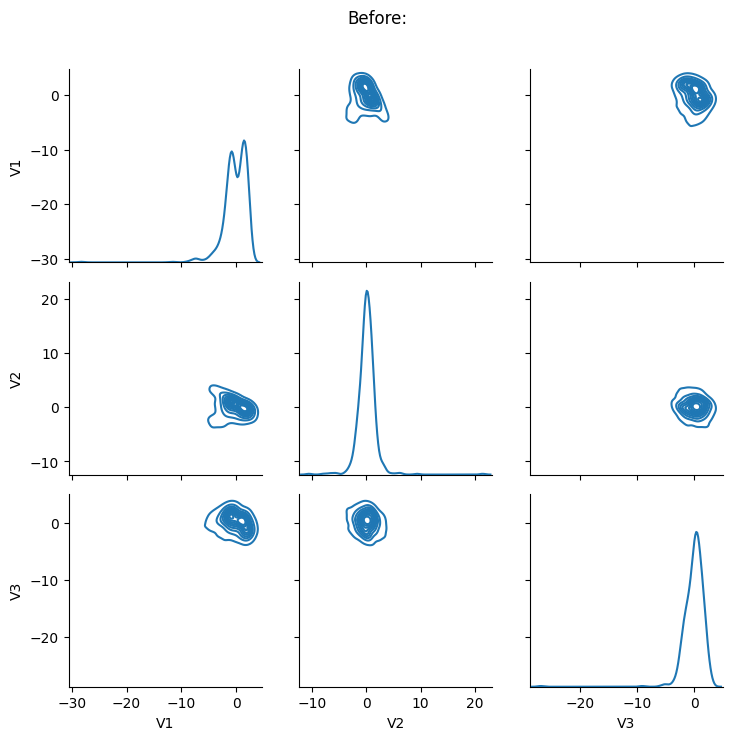

In [36]:
g = sns.PairGrid(train.drop(columns=['ID']).iloc[:,:3].sample(600, random_state=15))
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Before:')
g.map_diag(sns.kdeplot)
g.map_offdiag(sns.kdeplot);

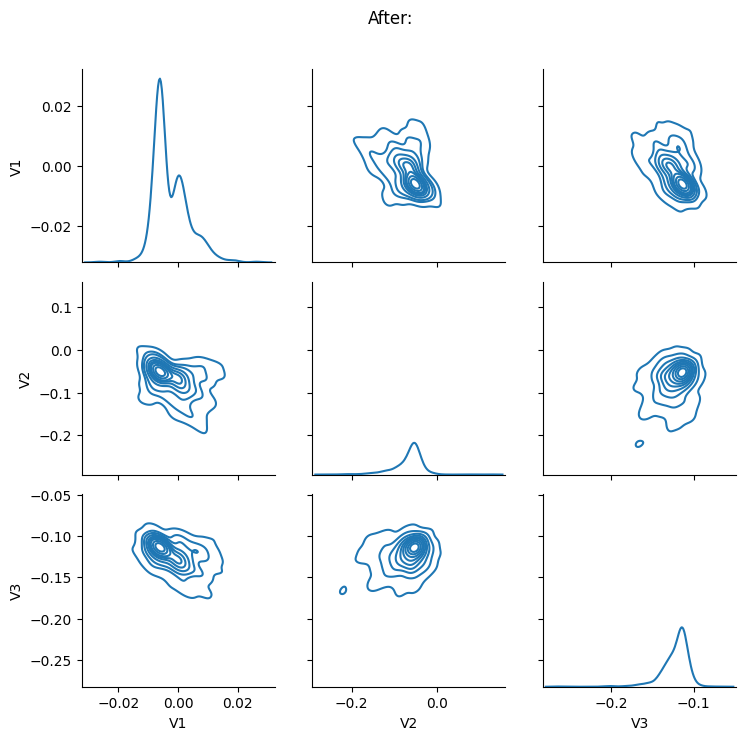

In [37]:
g = sns.PairGrid(pd.DataFrame(train_x, columns=train_x.columns).iloc[:,:3].sample(600, random_state=15))
plt.subplots_adjust(top=0.9)
g.fig.suptitle('After:')
g.map_diag(sns.kdeplot)
g.map_offdiag(sns.kdeplot);

In [38]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture

gmm = GaussianMixture(n_components=2, random_state=0)
gmm.fit(train_x)

BGM = BayesianGaussianMixture(n_components=2, random_state=42, verbose=0)
BGM.fit(train_x)

cluster_data = gmm.score_samples(train_x)
cluster_data2 = BGM.score_samples(train_x)

train_x['CLUSTER_1'] = cluster_data
train_x['CLUSTER_2'] = cluster_data2

In [39]:
train_x.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,V29,V30,CLUSTER_1,CLUSTER_2
0,-0.007913,-0.087434,-0.114101,0.017489,0.045063,0.369799,-0.015878,0.094977,0.009748,0.181548,...,6.558152,-0.216549,-0.170033,0.095700,-6.350469,-31.797581,0.366771,-0.083266,9.024127,8.857103
1,-0.008698,-0.069483,-0.102464,-0.001609,0.055340,0.382600,-0.031386,0.474307,-0.025045,0.151404,...,-2.188781,-0.499281,0.401457,-0.091138,12.358559,33.513973,0.196528,-0.160072,13.495593,13.866735
2,-0.005797,-0.044107,-0.110132,0.011407,0.058187,0.268627,-0.026381,0.112150,0.034631,0.103889,...,-0.035505,-0.124014,-0.105727,0.179813,22.832037,22.712382,-0.014835,-0.069684,51.309568,51.663707
3,-0.005170,-0.053997,-0.113105,0.012034,0.050202,0.259905,-0.038603,-0.322131,0.049097,0.133013,...,0.107275,-0.070644,-0.042808,0.098617,-11.139318,-35.671833,0.002459,-0.004297,17.626388,18.211278
4,-0.006479,-0.054567,-0.117146,0.010757,0.100613,0.373315,-0.032282,0.488038,0.040528,0.107477,...,-0.975994,0.081998,0.074302,-0.071780,0.828521,38.332976,0.059816,-0.067043,41.911602,42.415993


In [40]:
model = EllipticEnvelope(support_fraction = 0.994,contamination = val_contamination, random_state = 42)
model.fit(train_x)

EllipticEnvelope(contamination=0.0010551491277433877, random_state=42,
                 support_fraction=0.994)

In [41]:
val_x = val.drop(columns=['Class'])
val_y = val['Class']

In [42]:
def get_pred_label(model_pred):
    model_pred=np.where(model_pred==1, 0, model_pred)
    model_pred=np.where(model_pred==-1, 1, model_pred)
    return model_pred

In [47]:
clusters = gmm.score_samples(val_x)
cluster_data = BGM.score_samples(val_x)

val_x['CLUSTER_1'] = clusters
val_x['CLUSTER_2'] = cluster_data

In [48]:
val_pred = model.predict(val_x)
val_pred = get_pred_label(val_pred)
val_pred[:5]

array([1, 1, 1, 1, 1])

In [51]:
val_x

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V23,V24,V25,V26,V27,V28,V29,V30,CLUSTER_1,CLUSTER_2
0,-0.200313,1.075963,0.709967,-0.181398,0.585648,-0.061915,0.808468,0.143372,-0.818940,-0.452878,...,-0.505799,-0.754661,-0.174943,0.314060,2.201624,0.915952,-0.370294,-1.505419,-17921.715469,-18850.958738
1,0.325518,0.145409,-0.185150,1.098475,0.771684,1.423510,0.045165,0.780324,-0.784635,0.760978,...,-0.090453,-1.540963,0.480507,0.375969,0.077729,-0.209796,0.146091,-0.892722,-11379.212795,-11845.472612
2,0.492295,0.383674,0.008124,1.704583,-0.031643,-0.698576,0.480528,-0.522834,-0.744366,0.972593,...,-0.219767,0.900337,1.010308,0.168717,-0.368225,0.046330,0.185144,-1.129183,-28145.378463,-29170.865310
3,0.359139,-0.272172,0.099960,0.332433,0.225500,1.558432,-0.415161,1.067647,0.222035,-0.127425,...,0.335944,-1.283929,0.102039,0.723249,0.210615,-0.153059,0.326846,-1.021239,-14546.467464,-15090.694544
4,-0.517493,0.721553,0.236371,-0.608130,0.141679,-0.057915,0.753984,-1.473389,1.425831,2.826338,...,-0.178626,0.228897,0.063895,0.419004,-0.675590,-4.108040,-0.122067,-0.442229,-37969.659576,-40237.488886
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28457,-0.277085,1.193525,-0.316557,0.704452,0.532502,-0.347383,1.156062,0.575972,-1.065877,0.003747,...,-0.643425,-0.001832,0.010928,-0.785094,2.326182,1.733023,0.254065,1.354923,-8715.340894,-9150.346899
28458,-0.404028,0.484139,-0.746002,-0.316995,0.927781,-0.583893,0.852293,0.952761,-0.729596,-1.607442,...,0.617865,0.921197,-0.417891,0.685801,-1.250564,-0.827103,1.061900,1.419734,-18365.948475,-19061.586798
28459,-0.208530,0.982731,-0.209459,0.683324,0.539206,-0.335420,1.246099,-2.222158,-0.342215,0.197865,...,-0.487722,-0.105693,-0.006007,-0.645263,3.553499,2.121441,0.615582,1.239696,-3768.444384,-3986.635361
28460,1.098636,-0.215983,-0.980526,0.202031,0.034664,-0.575303,-0.017183,-0.334648,0.518825,0.487608,...,1.298761,-0.666270,-0.665119,0.551376,-0.689016,-0.965600,-0.365526,1.471177,-106165.606675,-110284.536872


In [52]:
val_score = model.score_samples(val_x)
val_score_df = pd.DataFrame(val_score, columns=["ab score"])

In [58]:
val_score[val_pred == 1]

array([-9.42112661e+06, -3.46551757e+06, -2.55087611e+07, ...,
       -3.31249458e+05, -3.62302866e+08, -3.35297457e+05])

## 제출: Normalizer → Elliptic Envelope (어느 지표가 맞는지 확인용)

val에서 두 지표가 엇갈렸습니다.
- val macro-F1: Normalizer 버전 **0.9236** > 지금 모델 0.8928 (threshold 근처 사기 3건 차이)
- PR-AUC: Normalizer 버전 0.6716 < 지금 모델 **0.7751** (전체 줄 세우기 품질)

리더보드로 **어느 지표가 test에서 더 믿을 만한 길잡이인지** 확인합니다.

- 위 셀들에서 `train_x`, `val`이 여러 번 변환됐을 수 있으므로 CSV를 **새로 읽어서** 시작합니다
- 변환 결과는 원본에 덮어쓰지 않고 새 변수에 담습니다 (몇 번 실행해도 결과가 같도록)
- RobustScaler는 Elliptic Envelope에서 효과가 상쇄되므로 빼고, GMM 피처도 효과가 없어서 뺍니다
- 모델 설정은 처음 제출과 같습니다: `support_fraction=0.994`, `contamination=val 사기 비율`

In [59]:
from sklearn.preprocessing import Normalizer
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import f1_score, average_precision_score

# 원본을 새로 읽기 (위에서 변환된 변수와 섞이지 않게)
tr_raw = pd.read_csv('../data/train.csv')
va_raw = pd.read_csv('../data/val.csv')
te_raw = pd.read_csv('../data/test.csv')
V_COLS = [f'V{i}' for i in range(1, 31)]

normalizer = Normalizer()   # 각 거래(행)를 길이 1로 (학습할 것이 없는 변환)
X_tr_n = normalizer.transform(tr_raw[V_COLS].values)
X_va_n = normalizer.transform(va_raw[V_COLS].values)
X_te_n = normalizer.transform(te_raw[V_COLS].values)

y_va = va_raw['Class'].values
contamination = y_va.sum() / (y_va == 0).sum()   # val 사기 비율 (약 0.1055%)

ee_norm = EllipticEnvelope(support_fraction=0.994, contamination=contamination, random_state=42).fit(X_tr_n)

# val 확인 (재현 실험과 같은 값이 나와야 함: F1 0.9236, 25건 맞힘, 29건 예측)
val_pred_n = (ee_norm.predict(X_va_n) == -1).astype(int)
print(f'val macro-F1: {f1_score(y_va, val_pred_n, average="macro"):.4f} / 맞힌 사기 {(val_pred_n & y_va).sum()}/30 / '
      f'예측 {val_pred_n.sum()}건 / PR-AUC {average_precision_score(y_va, -ee_norm.score_samples(X_va_n)):.4f}')

# test 예측과 제출 파일
test_pred_n = (ee_norm.predict(X_te_n) == -1).astype(int)
submission = pd.read_csv('../data/sample_submission.csv')
assert (submission['ID'].values == te_raw['ID'].values).all()   # 행 순서 확인
submission['Class'] = test_pred_n
submission.to_csv('../submissions/submission_phase4c_ee_normalizer.csv', index=False)
print(f'test 사기 예측 {test_pred_n.sum()}건 -> submissions/submission_phase4c_ee_normalizer.csv')

# 지금까지 제출과 비교
for name, file in [('처음 EE (Public 0.9248)', 'submit.csv'), ('1차 + 0.12% (Public 0.9305)', 'submission_phase4c_ee_raw_c012.csv')]:
    prev = pd.read_csv(f'../submissions/{file}')['Class'].values
    print(f'{name}: {prev.sum()}건 / 둘 다 사기 {(test_pred_n & prev).sum()}건 / '
          f'Normalizer만 {(test_pred_n & (prev == 0)).sum()}건 / 이전만 {((test_pred_n == 0) & prev).sum()}건')

val macro-F1: 0.9236 / 맞힌 사기 25/30 / 예측 29건 / PR-AUC 0.6716
test 사기 예측 292건 -> submissions/submission_phase4c_ee_normalizer.csv
처음 EE (Public 0.9248): 303건 / 둘 다 사기 282건 / Normalizer만 10건 / 이전만 21건
1차 + 0.12% (Public 0.9305): 318건 / 둘 다 사기 292건 / Normalizer만 0건 / 이전만 26건


## 실험 ④: val의 정상 거래를 학습에 추가하기

**base**: 원본 V1~V30, MCD(support_fraction=0.994)의 1차 공분산, threshold = train 점수 상위 0.12% → Public 0.9305 / Private 0.9054

**아이디어**: train에는 정답이 없어서 사기가 약 0.12% 섞여 있습니다. val에는 정답이 있으니 **확실한 정상 28,432건**을 골라
"정상의 모양"을 배우는 데 보탤 수 있습니다. 특히 평면 밖 정상이 약 3,300건 늘어나는데, base의 오탐 5건이 전부 평면 밖 정상이었습니다.

**문제**: val을 학습에 쓰면 val로 채점할 수 없습니다 (시험 문제로 공부한 셈).

**해결: 5겹 교차검증 (Stratified 5-Fold)**
1. val을 5조각으로 나눕니다 (조각마다 사기 6건씩 고르게)
2. 한 조각은 채점용으로 남기고, 나머지 4조각의 **정상 거래만** train에 보태서 학습
3. 남겨둔 조각을 채점 → 5번 돌아가며 반복하면 val 전체가 "학습에 안 쓰인 상태로" 한 번씩 채점됨

**한 번에 하나만 바꾸기**: threshold 규칙은 base와 같게 둡니다 (원래 train 113,842건의 점수 상위 0.12%).
바뀌는 건 "정상 기준(평균·공분산)을 잡는 데이터"뿐입니다.

조각마다 모델 점수의 크기가 조금씩 다르므로, 점수를 **"threshold의 몇 배인가"** 로 바꿔서 모은 뒤 PR-AUC를 계산합니다.
평면 위/밖 구분은 03b에서 저장한 평면 이탈 거리를 **분석용으로만** 씁니다 (모델 입력 아님).

MCD를 6번(base 1번 + 5조각) 학습해서 6~10분 걸립니다.

In [ ]:
import time
from scipy.linalg import pinvh
from sklearn.covariance import MinCovDet
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, average_precision_score

# 원본을 새로 읽기 (위 셀들에서 변환된 변수와 섞이지 않게)
tr_raw = pd.read_csv('../data/train.csv')
va_raw = pd.read_csv('../data/val.csv')
V_COLS = [f'V{i}' for i in range(1, 31)]
X_train = tr_raw[V_COLS].values
X_val = va_raw[V_COLS].values
y_val = va_raw['Class'].values
on_plane = pd.read_pickle('../data/val_fe.pkl')['off_plane_dist'].values < 1e-6   # 분석용 (03b의 평면)

CONT = 0.0012   # base와 같은 threshold 규칙: train 점수 상위 0.12%

def fit_scorer(X_fit):
    # MCD 1차 공분산으로 마할라노비스 거리 제곱을 계산하는 함수를 돌려줌
    mcd = MinCovDet(support_fraction=0.994, random_state=42).fit(X_fit)
    loc, prec = mcd.raw_location_, pinvh(mcd.raw_covariance_)
    return lambda X: np.sum(((X - loc) @ prec) * (X - loc), axis=1)

# base: train만으로 학습 (val 전체를 한 번에 채점해도 학습에 안 쓰였으므로 공정)
t0 = time.time()
base_scorer = fit_scorer(X_train)
base_th = np.quantile(base_scorer(X_train), 1 - CONT)
base_ratio = base_scorer(X_val) / base_th   # threshold의 몇 배인가 (1 이상이면 사기 예측)
print(f'base 학습: {time.time() - t0:.0f}초')

# ④: val을 5조각으로 나눠 교차검증
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aug_ratio = np.zeros(len(y_val))
for fold, (fit_idx, hold_idx) in enumerate(skf.split(X_val, y_val), start=1):
    t0 = time.time()
    val_normals = X_val[fit_idx][y_val[fit_idx] == 0]   # 학습용 4조각의 정상만
    scorer = fit_scorer(np.vstack([X_train, val_normals]))
    th = np.quantile(scorer(X_train), 1 - CONT)         # threshold 규칙은 base와 동일
    aug_ratio[hold_idx] = scorer(X_val[hold_idx]) / th  # 남겨둔 조각만 채점
    print(f'조각 {fold}: 정상 {len(val_normals)}건 추가, 채점 {len(hold_idx)}건 (사기 {y_val[hold_idx].sum()}건), {time.time() - t0:.0f}초')

In [ ]:
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 글꼴
plt.rcParams['axes.unicode_minus'] = False      # 로그 축의 마이너스 기호 깨짐 방지

def summarize(name, ratio):
    pred = (ratio >= 1).astype(int)
    fraud = y_val == 1
    return {'모델': name,
            'val macro-F1': round(f1_score(y_val, pred, average='macro'), 4),
            'PR-AUC': round(average_precision_score(y_val, ratio), 4),
            '예측 건수': int(pred.sum()),
            '평면 밖 사기 맞힘(/25)': int((pred & fraud & ~on_plane).sum()),
            '평면 위 사기 맞힘(/5)': int((pred & fraud & on_plane).sum()),
            '오탐': int((pred & ~fraud).sum()),
            '평면 위 사기 최고 순위': int(((-ratio).argsort().argsort() + 1)[fraud & on_plane].min())}

valnormal_table = pd.DataFrame([summarize('base (train만)', base_ratio),
                                summarize('④ train + val 정상 (5겹 교차검증)', aug_ratio)])
display(valnormal_table)

# 오탐과 사기의 점수가 어떻게 움직였는지: threshold 대비 배수, 로그 축
fig, ax = plt.subplots(figsize=(7, 6))
for mask, label, color in [((y_val == 0) & ~on_plane, '평면 밖 정상', 'lightgray'),
                           ((y_val == 1) & ~on_plane, '평면 밖 사기', 'red'),
                           ((y_val == 1) & on_plane, '평면 위 사기', 'blue')]:
    ax.scatter(base_ratio[mask], aug_ratio[mask], s=12 if color == 'lightgray' else 40, c=color, label=label, alpha=0.7)
lims = [min(base_ratio.min(), aug_ratio.min()), max(base_ratio.max(), aug_ratio.max())]
ax.plot(lims, lims, 'k:', lw=1)
ax.axvline(1, color='gray', lw=0.8); ax.axhline(1, color='gray', lw=0.8)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('base 점수 (threshold의 몇 배)'); ax.set_ylabel('④ 점수 (threshold의 몇 배)')
ax.set_title('val 정상을 추가하면 점수가 어떻게 바뀌나 (1 이상 = 사기 예측)')
ax.legend()
plt.show()

### 정리: val 정상을 더해도 아무것도 바뀌지 않았다

| | val macro-F1 | PR-AUC | 오탐 | 평면 위 사기 최고 순위 |
|---|---|---|---|---|
| base | 0.9166 | 0.7751 | 5 | 524위 |
| ④ train + val 정상 | 0.9166 | 0.7736 | 5 | 533위 |

- 두 점수의 순위 상관이 **0.9999**: 정상 22,700여 건을 더해도 정상 기준(평균·공분산)이 거의 그대로입니다.
  train 11만 건으로 이미 정상의 모양을 충분히 배웠고, train에 섞인 사기 0.12%도 support_fraction=0.994가 이미 잘라내고 있었다는 뜻입니다.
- **오탐 5건은 경계선 근처가 아니다.** 오탐 5건의 점수는 threshold의 39~1,262배로, 맞힌 사기(39~1,700배)와 같은 구간에 있습니다.
  반면 나머지 정상은 전부 0.1배 이하라, val에서는 threshold를 0.1배~39배 어디에 두어도 결과가 같습니다.
  즉 오탐 5건은 이 점수 기준으로는 **사기만큼 평면에서 멀리 떨어진 정상 거래**이고, threshold나 공분산을 다듬어서는 가를 수 없습니다.
- 결론: "평면에서 얼마나 벗어났나"라는 축 하나로 얻을 수 있는 건 다 얻었다.
  오탐을 줄이려면 **평면에서 멀리 떨어진 거래들 안에서 정상과 사기를 가르는 다른 기준**이 필요하고, 그건 정답 라벨을 쓰는 지도학습(Phase 5)의 영역이다.
  base는 그대로 유지하고 이 실험은 제출하지 않는다.